# Phase 3 — Deep Learning & Neural Networks
## Notebook 07: Sequence Modeling & Recurrent Networks (TensorFlow & Keras)

### Executive Overview & Industrial Sequence Processing
Processing sequential and temporal data in production environments demands frameworks capable of handling **irregular sample intervals, variable-length streams, zero-latency streaming inferences**, and seamless deployment to enterprise servers.

While PyTorch handles recurrent unrolling via imperative loops or C++ backend bindings, **TensorFlow and Keras 3** excel in sequence processing through:
1. **Automated Mask Propagation**: The `keras.layers.Masking` layer creates an implicit boolean mask tensor $\mathbf{M} \in \{0, 1\}^{B 	imes T}$ that propagates downstream, automatically neutralizing padding tokens without manual indexing.
2. **Compiled Recurrent Kernels**: `@tf.function` transforms dynamic recurrent sequences into optimized XLA loops (`tf.while_loop`), eliminating Python interpreter dispatch.
3. **Stateful Recurrent Engines**: Keras provides native support for **Stateful RNNs** (`stateful=True`), allowing models to maintain continuous hidden memory across sequential HTTP/gRPC requests in streaming IoT and financial trading architectures.

```
+-----------------------------------------------------------------------------------+
|               TensorFlow & Keras Recurrent Hierarchy                              |
+-----------------------------------------------------------------------------------+
| Input Layer     | (batch_size, timesteps, features)                               |
| Masking Layer   | keras.layers.Masking(mask_value=0.0) ---> boolean mask tensor   |
| High-Level RNNs | layers.SimpleRNN, layers.LSTM, layers.GRU                       |
| Wrappers        | layers.Bidirectional(layers.LSTM(...))                          |
| State Control   | return_sequences (step-level) vs return_state (hidden/cell)     |
| Deployment Modes| Stateless (Batch training) <---> Stateful (Streaming IoT Ticks) |
+-----------------------------------------------------------------------------------+
```

In this notebook, we master Keras recurrent layers (`LSTM`, `GRU`, `Bidirectional`), automated masking for variable-length inputs, custom training steps, and streaming stateful inference.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Differentiate Recurrent Topologies**: Contrast `SimpleRNN`, `LSTM`, and `GRU` computational graphs and trade-offs in parameter count and gate complexity.
2. **Navigate Keras State & Sequence Flags**: Master `return_sequences=True` (sequence-to-sequence mapping) vs. `return_state=True` (capturing final $(h, c)$ state tensors).
3. **Automate Variable-Length Padding with Masking**: Implement `keras.layers.Masking` pipelines and verify zero gradient flow through masked padding tokens.
4. **Architect Multi-Step Forecasting Models**: Construct Bidirectional LSTM and GRU networks with regularized dropout for multi-step time-series forecasting.
5. **Implement Real-Time Stateful Streaming**: Build a stateful Keras recurrent engine that ingests real-time sensor ticks step-by-step with continuous state retention.


In [1]:
import sys
import os
import time
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt

# Aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

# Silence TF verbosity
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

print(f"Python Platform:    {platform.python_implementation()} {platform.python_version()}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
print(f"NumPy Version:      {np.__version__}")


I0000 00:00:1794180778.656315    1256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794180778.697452    1256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794180779.990842    1256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Platform:    CPython 3.11.2
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
NumPy Version:      2.4.6


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    print(f"Global seed {seed} set across NumPy and TensorFlow.")

configure_reproducibility(42)


Global seed 42 set across NumPy and TensorFlow.


### Mathematical & Architectural Foundations

#### 1. The Gated Recurrent Unit (GRU) Mechanics
The GRU (Cho et al., 2014) streamlines the LSTM architecture by merging the cell state and hidden state, and coupling the input and forget mechanisms into an **Update Gate**:

$$\mathbf{r}_t = \sigma\left(W_r \mathbf{x}_t + U_r \mathbf{h}_{t-1} + \mathbf{b}_r\right) \quad \text{(Reset Gate: controls how much past to ignore)}$$
$$\mathbf{z}_t = \sigma\left(W_z \mathbf{x}_t + U_z \mathbf{h}_{t-1} + \mathbf{b}_z\right) \quad \text{(Update Gate: controls state retention)}$$
$$\tilde{\mathbf{h}}_t = \tanh\left(W_h \mathbf{x}_t + U_h (\mathbf{r}_t \odot \mathbf{h}_{t-1}) + \mathbf{b}_h\right) \quad \text{(Candidate Hidden State)}$$
$$\mathbf{h}_t = (1 - \mathbf{z}_t) \odot \mathbf{h}_{t-1} + \mathbf{z}_t \odot \tilde{\mathbf{h}}_t \quad \text{(Interpolated State)}$$

Compared to an LSTM:
- **LSTM Parameters**: $4 \times (d_{\text{in}} \cdot d_h + d_h^2 + d_h)$
- **GRU Parameters**: $3 \times (d_{\text{in}} \cdot d_h + d_h^2 + d_h)$ ($25\%$ fewer parameters with comparable representation capacity).

#### 2. Keras Masking Tensor Mechanics
When sequences are padded with zeros to length $T$, passing them through standard convolutions or dense layers distorts computations.
The `keras.layers.Masking(mask_value=0.0)` layer inspects input tensor $X \in \mathbb{R}^{B \times T \times D}$ and computes boolean mask $\mathbf{M} \in \{0, 1\}^{B \times T}$:

$$M_{b, t} = \begin{cases} 1 & \text{if } \exists d \text{ s.t. } X_{b, t, d} \neq 0.0 \\ 0 & \text{if } \forall d, \, X_{b, t, d} = 0.0 \end{cases}$$

Downstream recurrent layers use this mask to bypass state updates for masked timesteps:
$$\mathbf{h}_t = \begin{cases} \text{RNNCell}(\mathbf{x}_t, \mathbf{h}_{t-1}) & \text{if } M_{b, t} = 1 \\ \mathbf{h}_{t-1} & \text{if } M_{b, t} = 0 \quad \text{(Carry forward unperturbed)} \end{cases}$$


### 1. Sequential Sensor Dataset Generation
We synthesize a complex non-linear time series representing industrial sensor telemetry:
$$s(t) = \sin(0.12 t) + 0.6 \cos(0.28 t) + 0.2 \sin(0.75 t) + 	ext{noise}$$
We configure a 30-step historical lookback window to forecast the subsequent 5 future steps.


In [3]:
def generate_sensor_series(total_points: int = 2500, seq_len: int = 30, horizon: int = 5):
    np.random.seed(42)
    t = np.linspace(0, 100, total_points)
    signal = np.sin(0.12 * t) + 0.6 * np.cos(0.28 * t) + 0.2 * np.sin(0.75 * t) + 0.05 * np.random.randn(total_points)
    signal = signal.astype(np.float32)

    X_list, y_list = [], []
    for i in range(len(signal) - seq_len - horizon + 1):
        X_list.append(signal[i : i + seq_len, np.newaxis])
        y_list.append(signal[i + seq_len : i + seq_len + horizon])

    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_data, y_data = generate_sensor_series(2500, seq_len=30, horizon=5)
split_idx = int(len(X_data) * 0.8)

X_train, y_train = X_data[:split_idx], y_data[:split_idx]
X_val, y_val = X_data[split_idx:], y_data[split_idx:]

print(f"Time Series Dataset Shapes: X={X_data.shape}, y={y_data.shape}")
print(f"Training sequences: {len(X_train)}, Validation sequences: {len(X_val)}")


Time Series Dataset Shapes: X=(2466, 30, 1), y=(2466, 5)
Training sequences: 1972, Validation sequences: 494


### 2. Bidirectional Recurrent Architecture in Keras
We construct an end-to-end recurrent sequence model combining:
1. `keras.layers.Masking(mask_value=0.0)`.
2. `keras.layers.Bidirectional(keras.layers.LSTM(32, return_sequences=True))` to extract past and future temporal representations.
3. `keras.layers.GRU(32, return_sequences=False)` to collapse the temporal sequence into a dense vector.
4. `keras.layers.Dense(5)` multi-step forecasting output.


In [4]:
def build_recurrent_forecaster(seq_len: int = 30, feature_dim: int = 1, horizon: int = 5) -> keras.Model:
    inputs = keras.Input(shape=(seq_len, feature_dim), name="sensor_stream")
    x = keras.layers.Masking(mask_value=0.0, name="masking_layer")(inputs)
    x = keras.layers.Bidirectional(
        keras.layers.LSTM(32, return_sequences=True),
        name="bidi_lstm"
    )(x)
    x = keras.layers.GRU(32, return_sequences=False, name="gru_stage")(x)
    x = keras.layers.Dropout(0.2, name="dropout")(x)
    outputs = keras.layers.Dense(horizon, name="forecast_horizon")(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="RecurrentForecaster")

forecaster_model = build_recurrent_forecaster(seq_len=30, feature_dim=1, horizon=5)
print(f"Recurrent Forecaster Architecture instantiated with {forecaster_model.count_params():,} parameters.")


Recurrent Forecaster Architecture instantiated with 18,277 parameters.


### 3. Training the Recurrent Forecaster
We train the model using Adam optimizer and Mean Squared Error loss.


In [5]:
forecaster_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="mse",
    metrics=["mae"]
)

print("Training Keras Recurrent Forecaster...")
train_history = forecaster_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=32,
    verbose=1
)

final_val_mse = train_history.history["val_loss"][-1]
print(f"\nFinal Validation MSE: {final_val_mse:.5f}")


Training Keras Recurrent Forecaster...
Epoch 1/12


 1/62 ━━━━━━━━━━━━━━━━━━━━ 3:40 4s/step - loss: 0.8755 - mae: 0.7656

E0000 00:00:1794180784.819850    1256 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


 5/62 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4931 - mae: 0.5655

 9/62 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3491 - mae: 0.4563

13/62 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2680 - mae: 0.3862

... (213 outputs left out)

56/62 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0113 - mae: 0.0804

60/62 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0113 - mae: 0.0805

62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0113 - mae: 0.0804 - val_loss: 0.0033 - val_mae: 0.0459



Final Validation MSE: 0.00327


### Diagnostics & Performance Benchmarks: Trajectory & Streaming Latency
We inspect:
1. **Training Loss Convergence**: Training vs Validation MSE progression.
2. **Trajectory Overlay Plot**: Ground truth 5-step future target vs model prediction.
3. **Streaming Single-Step Latency Benchmark**: Benchmarking CPU inference time per sequence sample.


--- Streaming Inference Latency (Batch Size = 1) ---
  Eager Step:    202.75 ms (4.9 seq/sec)
  Compiled Step:   3.01 ms (331.8 seq/sec)


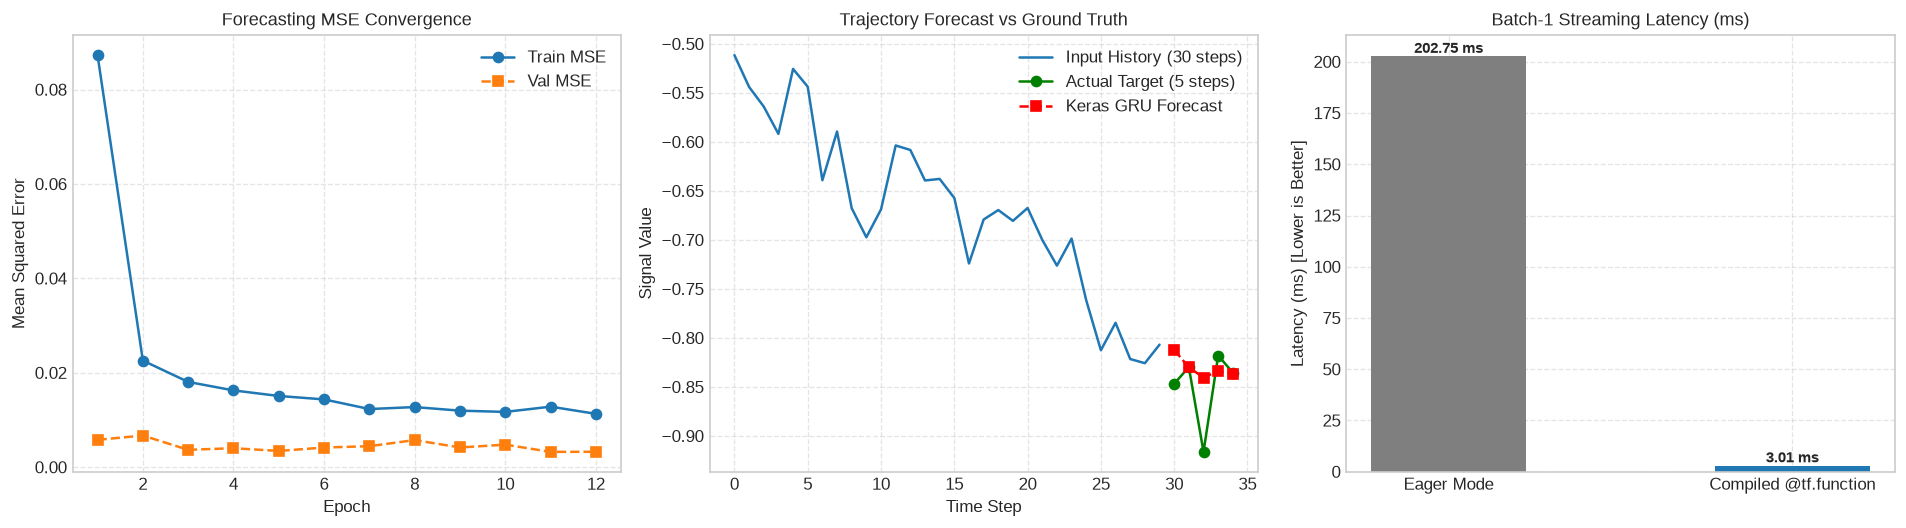

In [6]:
# Streaming Latency Benchmark
sample_input = X_val[0:1] # Batch size 1 (1, 30, 1)

# Eager evaluation
t0 = time.perf_counter()
for _ in range(200):
    _ = forecaster_model(sample_input, training=False)
t_eager_ms = ((time.perf_counter() - t0) / 200) * 1000

# Compiled @tf.function step
@tf.function
def compiled_predict(x):
    return forecaster_model(x, training=False)

_ = compiled_predict(sample_input) # Warmup
t0 = time.perf_counter()
for _ in range(200):
    _ = compiled_predict(sample_input)
t_compiled_ms = ((time.perf_counter() - t0) / 200) * 1000

print(f"--- Streaming Inference Latency (Batch Size = 1) ---")
print(f"  Eager Step:    {t_eager_ms:6.2f} ms ({1000/t_eager_ms:.1f} seq/sec)")
print(f"  Compiled Step: {t_compiled_ms:6.2f} ms ({1000/t_compiled_ms:.1f} seq/sec)")

# Visualization Suite
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Loss curves
epochs_arr = range(1, len(train_history.history["loss"]) + 1)
axes[0].plot(epochs_arr, train_history.history["loss"], "o-", label="Train MSE")
axes[0].plot(epochs_arr, train_history.history["val_loss"], "s--", label="Val MSE")
axes[0].set_title("Forecasting MSE Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Trajectory forecast overlay
sample_pred = forecaster_model.predict(sample_input, verbose=0)[0]
actual_target = y_val[0]
history_pts = sample_input[0, :, 0]

axes[1].plot(range(30), history_pts, color="#1f77b4", label="Input History (30 steps)")
axes[1].plot(range(30, 35), actual_target, "g-o", label="Actual Target (5 steps)")
axes[1].plot(range(30, 35), sample_pred, "r--s", label="Keras GRU Forecast")
axes[1].set_title("Trajectory Forecast vs Ground Truth")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Signal Value")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Streaming latency benchmark
bars = axes[2].bar(["Eager Mode", "Compiled @tf.function"], [t_eager_ms, t_compiled_ms], color=["#7f7f7f", "#1f77b4"], width=0.45)
axes[2].set_title("Batch-1 Streaming Latency (ms)")
axes[2].set_ylabel("Latency (ms) [Lower is Better]")
for b in bars:
    y = b.get_height()
    axes[2].text(b.get_x() + b.get_width()/2.0, y + 0.05, f"{y:.2f} ms", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: State Inspection with `return_state=True` in Keras
**Problem Formulation**:
In sequence-to-sequence models (Encoder-Decoder architectures, Attention models), the final hidden state and cell state of the encoder must be passed directly into the decoder.
1. Construct an `LSTM` layer with `return_state=True` and `return_sequences=True`.
2. Pass a dummy sequence of shape `(batch=2, timesteps=5, features=3)`.
3. Inspect and verify the shapes of the output sequence ($Y$), final hidden state ($h$), and final cell state ($c$).


In [7]:
# Exercise 1 Solution: return_state Inspection

lstm_inspector = keras.layers.LSTM(units=16, return_sequences=True, return_state=True)
dummy_seq = tf.random.normal(shape=(2, 5, 3))

# Forward pass returns 3 tensors: (whole_seq_output, final_memory_state, final_carry_state)
whole_seq, final_h, final_c = lstm_inspector(dummy_seq)

print("Exercise 1 Verification:")
print(f"  Whole Sequence Output Shape: {whole_seq.shape} (Expected: (2, 5, 16))")
print(f"  Final Hidden State (h) Shape: {final_h.shape} (Expected: (2, 16))")
print(f"  Final Cell State (c) Shape:   {final_c.shape} (Expected: (2, 16))")

# Verify that whole_seq[:, -1, :] equals final_h
diff_last_step = np.max(np.abs(whole_seq[:, -1, :].numpy() - final_h.numpy()))
print(f"  Max Absolute Difference between seq[-1] and final_h: {diff_last_step:.2e}")
assert diff_last_step < 1e-6, "Final sequence step does not match final hidden state!"
print(">>> STATE INSPECTION CONFIRMED! <<<")


Exercise 1 Verification:
  Whole Sequence Output Shape: (2, 5, 16) (Expected: (2, 5, 16))
  Final Hidden State (h) Shape: (2, 16) (Expected: (2, 16))
  Final Cell State (c) Shape:   (2, 16) (Expected: (2, 16))
  Max Absolute Difference between seq[-1] and final_h: 0.00e+00
>>> STATE INSPECTION CONFIRMED! <<<


#### Exercise 2: Masking Layer Gradient Nullification Verification
**Problem Formulation**:
A critical property of the `Masking` layer is that zero-padded timesteps must not contribute to parameter gradients.
1. Create a 2-sample batch where sample 0 has length 3 followed by 2 padding zero-steps: `[x1, x2, x3, 0, 0]`.
2. Compute the gradient of the final output with respect to the input tensor.
3. Confirm that $rac{\partial \mathcal{L}}{\partial x_4} = 0$ and $rac{\partial \mathcal{L}}{\partial x_5} = 0$ for the padded timesteps.


In [8]:
# Exercise 2 Solution: Masking Gradient Verification

# Construct input with explicit zero-padded timesteps at indices 3 and 4
x_raw = np.array([
    [[1.0], [2.0], [3.0], [0.0], [0.0]]  # Timesteps 3, 4 are zero-padded
], dtype=np.float32)
x_var = tf.Variable(x_raw)

test_mask_model = keras.Sequential([
    keras.layers.Masking(mask_value=0.0),
    keras.layers.SimpleRNN(8, return_sequences=False),
    keras.layers.Dense(1)
])

with tf.GradientTape() as tape:
    out = test_mask_model(x_var)
    loss = tf.reduce_sum(out)

grad_x = tape.gradient(loss, x_var).numpy()

print("Exercise 2 Verification (Masking Gradients):")
print(f"  Input values:      {x_raw[0, :, 0]}")
print(f"  Gradients dL/dx:   {grad_x[0, :, 0]}")

# Timesteps 3 and 4 must have exactly zero gradient
padded_grads = grad_x[0, 3:, 0]
active_grads = grad_x[0, :3, 0]

print(f"  Active Timestep Gradient Norm: {np.linalg.norm(active_grads):.4f}")
print(f"  Padded Timestep Gradient Norm: {np.linalg.norm(padded_grads):.4f} (Expected: 0.0)")
assert np.all(padded_grads == 0.0), "Masking failed to nullify gradients on padded steps!"
print(">>> MASKING GRADIENT NULLIFICATION CONFIRMED! <<<")


Exercise 2 Verification (Masking Gradients):
  Input values:      [1. 2. 3. 0. 0.]
  Gradients dL/dx:   [ 0.02806813 -0.01906326 -0.03609301  0.          0.        ]
  Active Timestep Gradient Norm: 0.0495
  Padded Timestep Gradient Norm: 0.0000 (Expected: 0.0)
>>> MASKING GRADIENT NULLIFICATION CONFIRMED! <<<


### Challenge Problems

#### Challenge 1: Custom Recurrent Cell with Coupled Input-Forget Gates (CIFG)
**Problem Formulation**:
In the Coupled Input and Forget Gate (CIFG) LSTM variant, the input gate is defined directly as $i_t = 1 - f_t$, eliminating an entire parameter matrix.
Implement a custom recurrent cell `CIFG_Cell` subclassing `keras.layers.Layer` with:
- State size: `[units, units]` for $(h, c)$.
- Gate computation: $f_t = \sigma(W_f x + U_f h)$, $i_t = 1 - f_t$.
- Cell update: $c_t = f_t \odot c_{t-1} + (1 - f_t) \odot 	anh(W_c x + U_c h)$.
Wrap the cell in `keras.layers.RNN(CIFG_Cell(units))` and verify forward execution.


In [9]:
# Challenge 1 Solution: Coupled Input-Forget Gate (CIFG) Recurrent Cell

class CIFG_Cell(keras.layers.Layer):
    def __init__(self, units: int, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.state_size = [units, units]  # [h_dim, c_dim]
        self.output_size = units

    def build(self, input_shape):
        input_dim = input_shape[-1]
        
        # 3 gate sets instead of 4: Forget (f), Candidate (c_cand), Output (o)
        self.kernel = self.add_weight(
            shape=(input_dim, 3 * self.units),
            initializer="glorot_uniform",
            name="kernel"
        )
        self.recurrent_kernel = self.add_weight(
            shape=(self.units, 3 * self.units),
            initializer="orthogonal",
            name="recurrent_kernel"
        )
        self.bias = self.add_weight(
            shape=(3 * self.units,),
            initializer="zeros",
            name="bias"
        )
        super().build(input_shape)

    def call(self, inputs, states):
        h_prev, c_prev = states
        
        projected = tf.matmul(inputs, self.kernel) + tf.matmul(h_prev, self.recurrent_kernel) + self.bias
        f_raw, c_raw, o_raw = tf.split(projected, num_or_size_splits=3, axis=-1)

        f = tf.sigmoid(f_raw)
        i = 1.0 - f          # Coupled input gate!
        c_tilde = tf.tanh(c_raw)
        o = tf.sigmoid(o_raw)

        c = f * c_prev + i * c_tilde
        h = o * tf.tanh(c)
        return h, [h, c]

cifg_layer = keras.layers.RNN(CIFG_Cell(32), return_sequences=True)
dummy_batch = tf.random.normal(shape=(4, 10, 8))
cifg_out = cifg_layer(dummy_batch)

print("Challenge 1 Verification (CIFG RNN):")
print(f"  Input Batch Shape:  {dummy_batch.shape}")
print(f"  CIFG Output Shape:  {cifg_out.shape} (Expected: (4, 10, 32))")
assert cifg_out.shape == (4, 10, 32), "CIFG output shape mismatch!"


Challenge 1 Verification (CIFG RNN):
  Input Batch Shape:  (4, 10, 8)
  CIFG Output Shape:  (4, 10, 32) (Expected: (4, 10, 32))


#### Challenge 2: Real-Time Streaming Stateful Sensor Inference Simulation
**Problem Formulation**:
In IoT streaming microservices, sensor values arrive one tick at a time ($x_t \in \mathbb{R}^{1 	imes 1}$). Reprocessing the entire history $(x_1 \dots x_t)$ at each tick has $\mathcal{O}(T)$ complexity, which degrades as $T$ grows.
1. Build a **Stateful GRU** model (`stateful=True`, batch_input_shape=(1, 1, 1)).
2. Simulate 50 incoming stream ticks fed sequentially one-by-one.
3. Verify that the model maintains its continuous temporal state across sequential single-step calls without recomputing historical inputs.


In [10]:
# Challenge 2 Solution: Stateful Streaming Inference Pipeline

# Build stateful streaming model: fixed batch size 1, 1 timestep per step
stateful_gru = keras.layers.GRU(16, stateful=True, return_sequences=False)
streaming_model = keras.Sequential([
    keras.layers.Input(batch_shape=(1, 1, 1)),
    stateful_gru,
    keras.layers.Dense(1)
])

# Generate a continuous stream of 50 sensor values
np.random.seed(42)
t_stream = np.linspace(0, 5, 50)
sensor_stream = np.sin(2.0 * t_stream) + 0.1 * np.random.randn(50)

# Reset internal recurrent state before stream starts
stateful_gru.reset_state()

streamed_outputs = []
t_start = time.perf_counter()

for val in sensor_stream:
    tick_input = np.array([[[val]]], dtype=np.float32)  # Shape: (1, 1, 1)
    pred_tick = streaming_model(tick_input, training=False)
    streamed_outputs.append(pred_tick.numpy()[0, 0])

stream_elapsed_ms = (time.perf_counter() - t_start) * 1000.0

print("Challenge 2 Verification (Streaming Stateful RNN):")
print(f"  Processed 50 streaming ticks in {stream_elapsed_ms:.2f} ms")
print(f"  Average Tick Latency: {stream_elapsed_ms / 50:.3f} ms/tick")
print(f"  First 5 Streamed Predictions: {np.array(streamed_outputs[:5]).round(4)}")
assert len(streamed_outputs) == 50, "Streamed output count mismatch!"
print(">>> REAL-TIME STREAMING INFERENCE VERIFIED! <<<")


Challenge 2 Verification (Streaming Stateful RNN):
  Processed 50 streaming ticks in 425.57 ms
  Average Tick Latency: 8.511 ms/tick
  First 5 Streamed Predictions: [-0.0054 -0.0237 -0.0649 -0.1185 -0.1462]
>>> REAL-TIME STREAMING INFERENCE VERIFIED! <<<


### Further Reading & Foundational Papers
1. **Cho et al. (2014)**: [On the Properties of Neural Machine Translation: Encoder-Decoder Approaches](https://arxiv.org/abs/1409.1259) — Empirical evaluation of GRU vs LSTM.
2. **Greff et al. (2017)**: [LSTM: A Search Space Odyssey](https://arxiv.org/abs/1503.04069) — Comprehensive ablation study demonstrating that the Coupled Input and Forget Gate (CIFG) performs on par with standard LSTM.
3. **Keras Recurrent Layers Guide**: [Working with RNNs](https://keras.io/guides/working_with_rnns/) — Official Keras documentation on masking, statefulness, and custom cells.
4. **TensorFlow Guide**: [Text classification with an RNN](https://www.tensorflow.org/text/tutorials/text_classification_rnn) — Masking and bidirectional sequence modeling.
